# Оценка A/B-теста новой версии сайта интернет-магазина BitMotion Kit

- Автор: Чахлова Елизавета
- Дата: 21.10.2026

**Цели исследования.**
Необходимо выделить пользователей, которые участвуют в тесте `interface_eu_test`. 
Проверить равномерность распределения пользователей по группам и непересечение пользователей в группах.
Оценить достаточность выборки для получения статистически значимых результатов A/B-теста. Проверить гипотезу, что упрощение интерфейса приведёт к тому, что в течение семи дней после регистрации в системе конверсия зарегистрированных пользователей в покупателей увеличится как минимум на три процентных пункта.

## 2. Загрузите данные, оцените их целостность.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from scipy.stats import mannwhitneyu
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.proportion import proportions_ztest

In [ ]:
# participants = тут была загрузка данных пользователей
# events = тут была загрузка данных по событиям

### 3. По таблице `ab_test_participants` оцениваем корректность проведения теста:

 Выделяем пользователей, участвующих в тесте, и проверяем:

   - соответствие требованиям технического задания,

   - равномерность распределения пользователей по группам теста,

   - отсутствие пересечений с конкурирующим тестом (нет пользователей, участвующих одновременно в двух тестовых группах).

In [3]:
users_test = participants[participants['ab_test'] == 'interface_eu_test']

In [4]:
unique_users_test = users_test['group'].value_counts()
unique_users_test

p = 100*((unique_users_test.loc['B'] - unique_users_test.loc['A'])/unique_users_test.loc['B'])

print(f"Пользователей в группе A - {unique_users_test['A']}")
print(f"Пользователей в группе B - {unique_users_test['B']}")
print(f"Процентная разница мужду группой A и B составляет - {round(p, 2)}%")

Пользователей в группе A - 5383
Пользователей в группе B - 5467
Процентная разница мужду группой A и B составляет - 1.54%


In [5]:
users_test.duplicated('user_id').sum()

0

In [6]:
users_test['device'].value_counts()

Android    4859
PC         2764
iPhone     2107
Mac        1120
Name: device, dtype: int64

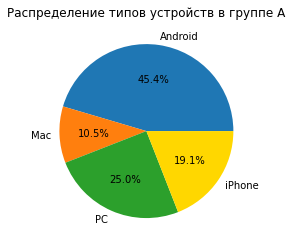

In [7]:
group_A_device = users_test[users_test['group'] == 'A'].groupby('device')['user_id'].nunique()
order = ['Android', 'Mac', 'PC', 'iPhone'] # Задаем нужный порядок категорий
group_A_device_ordered = group_A_device.reindex(order) # Изменяем порядок, чтобы упорядочить группы на круговой диаграмме

colors_list = ['#1f77b4', '#ff7f0e', '#2ca02c', '#ffd700'] # Задаем цвета для диаграммы
group_A_device_ordered.plot(
    title=f'Распределение типов устройств в группе A',
    ylabel='',
    xlabel='',
    kind='pie',
    colors=colors_list,
    autopct='%1.1f%%',          # показываем проценты
    legend=False               # убираем легенду
)
plt.show()

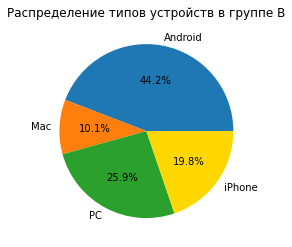

In [8]:
group_B_device = users_test[users_test['group'] == 'B'].groupby('device')['user_id'].nunique()
group_B_device_ordered = group_B_device.reindex(order)
group_B_device_ordered.plot(
    title=f'Распределение типов устройств в группе B',
    ylabel='',
    xlabel='',
    kind='pie',
    colors=colors_list,
    autopct='%1.1f%%',          # показываем проценты
    legend=False               # убираем легенду
)
plt.show()

In [9]:
group_A_device_ordered

device
Android    2445
Mac         566
PC         1346
iPhone     1026
Name: user_id, dtype: int64

**Промежуточный вывод**
- Тест соответствует требованиям технического задания, название теста `interface_eu_testa` и 2 тестовые группы `A` и `B`
- Пользователей в группе A - 5383, пользователей в группе B - 5467, процентная разница мужду группой A и B составляет - 1.54%
- user_id не дублируются в таблице participants, а значит нет пользователей, участвующих одновременно в двух тестовых группах
- по device пользователи распределены практически одинаково:

группа А
- Android    2445
- Mac         566
- PC         1346
- iPhone     1026

группа B
- Android    2414
- Mac         554
- PC         1418
- iPhone     1081

Оставим только события, связанные с участвующими в изучаемом тесте пользователями;

In [10]:
ab_test_events = events.merge(users_test, on='user_id', how='inner')
ab_test_events.head()

,user_id,event_dt,event_name,details,group,ab_test,device
0,5F506CEBEDC05D30,2020-12-06 14:10:01,registration,0.0,A,interface_eu_test,iPhone
1,5F506CEBEDC05D30,2020-12-07 01:25:14,login,NaN,A,interface_eu_test,iPhone
2,5F506CEBEDC05D30,2020-12-07 01:25:47,login,NaN,A,interface_eu_test,iPhone
3,5F506CEBEDC05D30,2020-12-09 12:40:49,login,NaN,A,interface_eu_test,iPhone
4,5F506CEBEDC05D30,2020-12-09 12:40:49,product_page,NaN,A,interface_eu_test,iPhone


In [11]:
events_reg = ab_test_events[ab_test_events['event_name'] == 'registration'][['user_id', 'event_dt']]
events_reg.head()

,user_id,event_dt
0,5F506CEBEDC05D30,2020-12-06 14:10:01
6,51278A006E918D97,2020-12-06 14:37:25
11,A0C1E8EFAD874D8B,2020-12-06 17:20:22
14,275A8D6254ACF530,2020-12-06 19:36:54
30,0B704EB2DC7FCA4B,2020-12-06 19:42:20


In [12]:
events_reg.duplicated('user_id').sum()

0

In [13]:
ab_test_events = ab_test_events.merge(events_reg, on='user_id', how='left', suffixes=('_event', '_reg'))
ab_test_events.head()

,user_id,event_dt_event,event_name,details,group,ab_test,device,event_dt_reg
0,5F506CEBEDC05D30,2020-12-06 14:10:01,registration,0.0,A,interface_eu_test,iPhone,2020-12-06 14:10:01
1,5F506CEBEDC05D30,2020-12-07 01:25:14,login,NaN,A,interface_eu_test,iPhone,2020-12-06 14:10:01
2,5F506CEBEDC05D30,2020-12-07 01:25:47,login,NaN,A,interface_eu_test,iPhone,2020-12-06 14:10:01
3,5F506CEBEDC05D30,2020-12-09 12:40:49,login,NaN,A,interface_eu_test,iPhone,2020-12-06 14:10:01
4,5F506CEBEDC05D30,2020-12-09 12:40:49,product_page,NaN,A,interface_eu_test,iPhone,2020-12-06 14:10:01


In [14]:
ab_test_events['days'] = ab_test_events['event_dt_event'] - ab_test_events['event_dt_reg']
ab_test_events['days'] = ab_test_events['days'].dt.days

In [15]:
# ab_test_events[(ab_test_events['event_name'] == 'purchase') & (ab_test_events['days'] < 7)].head()
ab_test_events = ab_test_events[ab_test_events['days'] < 7]

In [16]:
ab_test_events['group'].value_counts()

B    35187
A    33762
Name: group, dtype: int64

**Промежуточный вывод**


Оцениваем достаточность выборки

In [17]:
alpha = 0.05  # Уровень значимости
beta = 0.2  # Ошибка второго рода, часто 1 - мощность
power = 1 - beta  # Мощность теста
p = 0.3 # Базовый уровень доли
mde = 0.03  # Минимальный детектируемый эффект
effect_size = proportion_effectsize(p, p + mde)

# Инициализируем класс NormalIndPower
power_analysis = NormalIndPower()

# Расчёт размера выборки
sample_size = power_analysis.solve_power(
    effect_size = effect_size,
    power = power,
    alpha = alpha,
    ratio = 1 # Равномерное распределение выборок
)

print(f"Необходимый размер выборки для каждой группы: {int(sample_size)}")

Необходимый размер выборки для каждой группы: 3761


In [18]:
unique_users_reg = ab_test_events[ab_test_events['event_name'] == 'registration'].groupby('group')['user_id'].nunique()
unique_users_reg

group
A    5383
B    5467
Name: user_id, dtype: int64

In [19]:
unique_users_purchase = ab_test_events[(ab_test_events['event_name'] == 'purchase') & (ab_test_events['days'] < 7)].groupby('group')['user_id'].nunique()
unique_users_purchase

group
A    1480
B    1600
Name: user_id, dtype: int64

In [20]:
part_A = round(unique_users_purchase['A']/unique_users_reg['A'], 3)
part_B = round(unique_users_purchase['B']/unique_users_reg['B'], 3)
delta = round((part_B - part_A), 3) # разница доли между группами

print(
    f"Конверсия зарегистрированных пользователей в покупку в группе A составляет - {part_A} %.\n"
    f"Конверсия зарегистрированных пользователей в покупку в группе B составляет - {part_B} %.\n"
    f"Процентная разница мужду группой A и B составляет - {delta}%"
)

Конверсия зарегистрированных пользователей в покупку в группе A составляет - 0.275 %.
Конверсия зарегистрированных пользователей в покупку в группе B составляет - 0.293 %.
Процентная разница мужду группой A и B составляет - 0.018%


**Предварительный вывод**

Необходимый размер выборки для каждой группы - 3761, что меньше уникального кол-ва пользователей в каждой группе A - 5383, B - 5467. Конверсия зарегистрированных пользователей в покупку в группе A составляет - 0.275%.
Конверсия зарегистрированных пользователей в покупку в группе B составляет - 0.293%. Если посчитать вручную увеличение конверсии в контрольной группе А на 3 процентных пункта получается 0.275*1.03 = 0.283. Что меньше конверсии в тестовой группе В, следовательно скорее всего тест будет успешный. 

### Оценка результатов A/B-тестирования:

**Наша гипотеза:**

- H₀: конверсия регистрации в покупку в течение 7 дней в группе B не выше, чем в группе A.
- H₁: конверсия регистрации в покупку в течение 7 дней в группе B выше, чем в группе A.

In [21]:
# Фиксируем уровень значимости
alpha = 0.05
n_a, n_b = unique_users_reg['A'], unique_users_reg['B'] # Берём предыдущие значения по размерам выборок A и B 
m_a, m_b = unique_users_purchase['A'], unique_users_purchase['B'] # Берём предыдущие значения по количеству успехов в выборках A и B 

stat_ztest, p_value_ztest = proportions_ztest(
    [m_a, m_b],
    [n_a, n_b],
    alternative='smaller' # так как H_1: p_a < p_b
)

if p_value_ztest > alpha:
    print(f'pvalue={p_value_ztest} > {alpha}')
    print('Не получилось отвергнуть нулевую гипотезу')
else:
    print(f'pvalue={p_value_ztest} < {alpha}')
    print('Отвергаем нулевую гипотезу') 

pvalue=0.020306993983065475 < 0.05
Отвергаем нулевую гипотезу


#### Итоговый вывод

**Статистика по тесту**

Необходимый размер выборки для каждой группы - 3761, фактически группы были больше A - 5383, B - 5467, это позволило собрать больше данных.

Наша гипотеза состоит в том, что упрощение интерфейса приведёт к тому, что в течение семи дней после регистрации в системе конверсия зарегистрированных пользователей в покупателей увеличится как минимум на три процентных пункта.

Для односторонней проверки гипотезы можно сформулировать так:

* H₀: конверсия регистрации в покупку в течение 7 дней в группе B не выше, чем в группе A.
* H₁: конверсия регистрации в покупку в течение 7 дней в группе B выше, чем в группе A.

При таком варианте проверки полученное значение p-value = 0.0203, что меньше уровня значимости 0.05. Это значит, что обнаружено статистически значимое увеличение конверсии в группе В!

Допольнительно проверила, что конверсия зарегистрированных пользователей в покупку в группе A составляет - 0.275%.Конверсия зарегистрированных пользователей в покупку в группе B составляет - 0.293%.
По результатам теста видно увеличение коверсии на 1.8 п.п., что меньше целевого значения в 3 п.п., заложенного в гипотезу. Таким образом, хотя улучшение и является статистически значимым, оно не достигает желаемого бизнес-эффекта.

**Рекомендации**

По результатам экперимента видно увеличение коверсии на 1.8 п.п., что меньше целевого значения в 3 п.п., заложенного в гипотезу. Таким образом, хотя улучшение и является статистически значимым, оно не достигает желаемого бизнес-эффекта. Можно рекомендовать раскатить новую версию интерфейса, так как обнарущено улучшение целевой метрики. 